# 02 · Alignment checks (M2)

Do MFA's phone boundaries sit on the sound? TEAM.md asks for this before the 4,600-clip run:
if the pilot is wrong, everything downstream (durations, templates, A1/A2 audio) is wrong.

1. **Bookkeeping** — the guarantees `phones.csv` gives M3 and M4.
2. **Look at it** — log-mel spectrograms with MFA's boundaries drawn on top (the Praat check).
3. **Measure it** — silence should be quiet and boundaries should sit on energy changes.
4. **Durations** — per-phone frame counts, the target M3 models.

Inputs: `data/cache/phones.csv` and `excluded.csv` from `make phones`. Figures go to `outputs/figures/`.

In [1]:
import os, sys
from pathlib import Path
sys.path.insert(0, "..")
os.chdir("..")                      # run everything from the repo root, like the scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch
import torchaudio

from src.config import (FIGURES, LOG_CLAMP_MIN, MEL_KWARGS, METADATA_CLEAN,
                        SECONDS_PER_FRAME, SIL, WAV_DIR)
from src.data.textgrid_to_phones import EXCLUDED_CSV, PHONES_CSV
from src.utils import read_filelist

FIGURES.mkdir(parents=True, exist_ok=True)
phones = pd.read_csv(PHONES_CSV)
excluded = pd.read_csv(EXCLUDED_CSV)
meta = pd.read_csv(METADATA_CLEAN, dtype={"id": str}).set_index("id")
print(f"{phones.clip_id.nunique()} clips, {len(phones)} phones, {len(excluded)} excluded")

13100 clips, 949856 phones, 0 excluded


## 1 · Bookkeeping

In [2]:
per_clip = phones.groupby("clip_id").n_frames.sum()
ends = phones.start_frame + phones.n_frames
same = phones.clip_id.eq(phones.clip_id.shift(-1))

checks = {
    "every clip sums to n_frames in metadata": (per_clip == meta.loc[per_clip.index, "n_frames"]).all(),
    "every phone has >= 1 frame": (phones.n_frames >= 1).all(),
    "phones tile each clip with no gaps": (ends[same] == phones.start_frame.shift(-1)[same]).all(),
    "no spn left": (phones.phone != "spn").all(),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'FAIL'}  {name}")
print()
print("excluded by reason:", excluded.reason.value_counts().to_dict() or "none")
kept = set(phones.clip_id)
for split in ["train", "val", "test", "test_100"]:
    ids = set(read_filelist(split))
    print(f"{split:9s} {len(ids & kept):6d} / {len(ids)}")

OK   every clip sums to n_frames in metadata
OK   every phone has >= 1 frame
OK   phones tile each clip with no gaps
OK   no spn left

excluded by reason: none


train      12501 / 12501
val          300 / 300
test         299 / 299
test_100     100 / 100


## 2 · Look at it

Same mel recipe as the vocoder (`MEL_KWARGS`, natural log after the clamp). White lines are phone
boundaries, the strip above shows words. Things to look for: silences (`sil`) over the dark gaps,
fricatives (S, Z, SH) over high-frequency noise, vowels over the formant bands, stops (P, T, K)
starting on a closure gap.

In [3]:
MEL = torchaudio.transforms.MelSpectrogram(**MEL_KWARGS)

def log_mel(clip_id):
    wav, _ = sf.read(WAV_DIR / f"{clip_id}.wav", dtype="float32")
    return torch.log(MEL(torch.from_numpy(wav)).clamp(min=LOG_CLAMP_MIN)).numpy()


def plot_alignment(clip_id, start=0, n=None, ax=None):
    mel = log_mel(clip_id)
    rows = phones[phones.clip_id == clip_id]
    n = n or mel.shape[1] - start
    end = start + n
    ax = ax or plt.subplots(figsize=(16, 4))[1]
    ax.imshow(mel[:, start:end], origin="lower", aspect="auto", cmap="magma",
              extent=[start, end, 0, mel.shape[0]])
    for r in rows.itertuples():
        if r.start_frame + r.n_frames <= start or r.start_frame >= end:
            continue
        ax.axvline(r.start_frame, color="white", lw=0.8)
        mid = r.start_frame + r.n_frames / 2
        if start <= mid < end:
            ax.text(mid, 74, r.phone, color="white" if r.phone != SIL else "cyan",
                    ha="center", fontsize=8, fontweight="bold")
    words = rows[rows.word_idx >= 0].groupby("word_idx").agg(
        word=("word", "first"), s=("start_frame", "min"), e=("start_frame", "max"))
    for w in words.itertuples():
        mid = (w.s + w.e) / 2
        if start <= mid < end:
            ax.text(mid, 83, w.word, ha="center", fontsize=9, clip_on=False)
    ax.set_xlim(start, end)
    ax.set_ylabel("mel bin")
    ax.set_xlabel(f"frame ({SECONDS_PER_FRAME * 1000:.1f} ms)")
    ax.set_title(f"{clip_id}: {meta.loc[clip_id, 'text_clean'][:110]}", loc="left", fontsize=10, pad=18)
    return ax

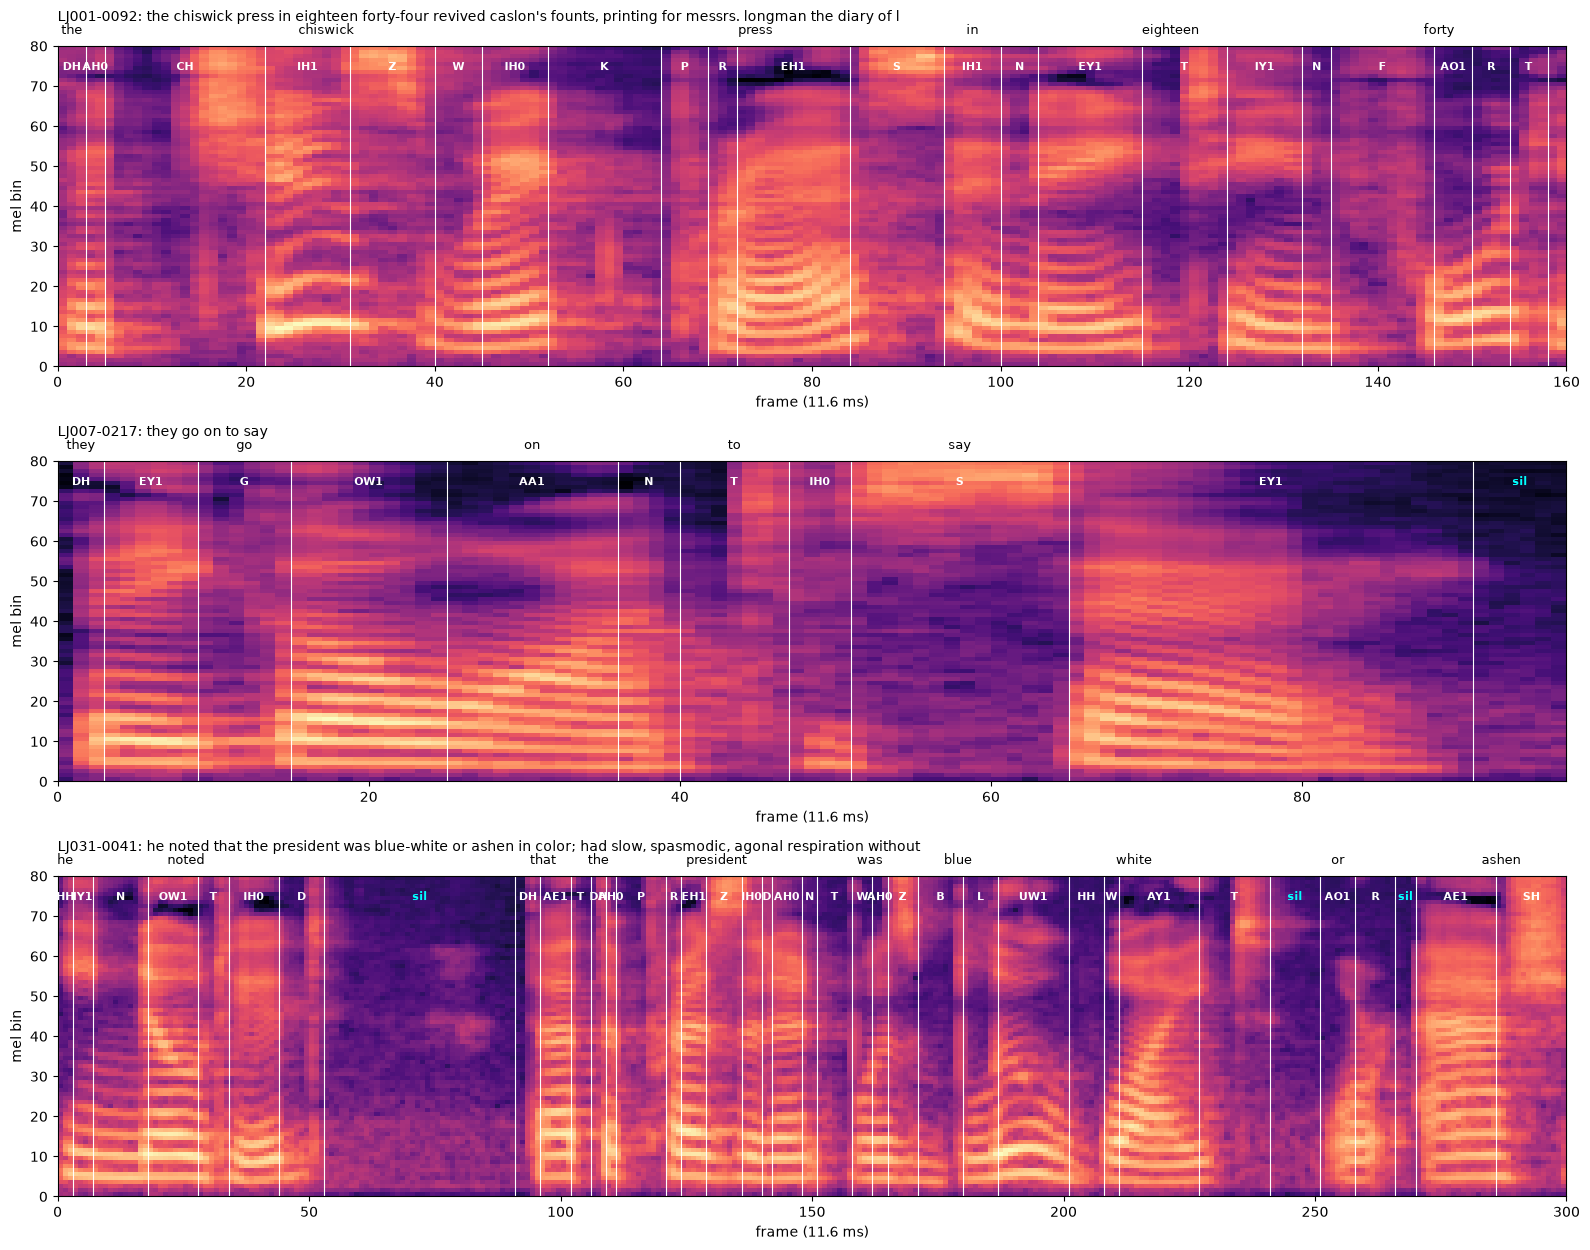

In [4]:
CLIPS = [("LJ001-0092", 0, 160),    # 'the chiswick press': the 17-frame CH looked long
         ("LJ007-0217", 0, None),    # shortest pilot clip
         ("LJ031-0041", 0, 300)]     # most internal pauses

fig, axes = plt.subplots(len(CLIPS), 1, figsize=(16, 4.2 * len(CLIPS)))
for ax, (cid, s, n) in zip(axes, CLIPS):
    plot_alignment(cid, s, n, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / "alignment_examples.png", dpi=110)
plt.show()

## 3 · Measure it

Two numbers that should be clearly true if the boundaries are right:

* **Silence is quiet.** Frame energy (mean log-mel, relative to the clip's loudest frame) for `sil`
  frames versus speech frames.
* **Boundaries sit on energy changes.** At every speech→silence boundary energy should drop, and at
  every silence→speech boundary it should rise. As a control, the same test with every boundary
  shifted by ±5 frames (58 ms) — a broken aligner would score about the same as the control.

In [5]:
VOWEL = phones.phone.str[-1].str.isdigit()
FRIC = phones.phone.isin(["S", "Z", "SH", "ZH", "F", "V", "TH", "DH", "HH"])
STOP = phones.phone.isin(["P", "B", "T", "D", "K", "G"])
NASAL = phones.phone.isin(["M", "N", "NG"])
phones["cls"] = np.select([phones.phone == SIL, VOWEL, FRIC, STOP, NASAL],
                          ["silence", "vowel", "fricative", "stop", "nasal"], "other")

rng = np.random.default_rng(42)
sample = rng.choice(sorted(kept), size=min(300, len(kept)), replace=False)

energy, cls, hits, control = [], [], [], []
for cid in sample:
    e = log_mel(cid).mean(axis=0)
    e = e - e.max()
    rows = phones[phones.clip_id == cid]
    frame_cls = np.repeat(rows.cls.values, rows.n_frames.values)
    energy.append(e); cls.append(frame_cls)

    is_sil = (rows.phone == SIL).values
    for k in range(1, len(rows)):
        if is_sil[k] == is_sil[k - 1]:
            continue
        b = int(rows.start_frame.values[k])
        rise = 1 if is_sil[k - 1] else -1          # silence -> speech should rise
        def moved(b):
            if b - 3 < 0 or b + 3 > len(e):
                return None
            return np.sign(e[b:b + 3].mean() - e[b - 3:b].mean()) == rise
        hits.append(moved(b))
        control.append(moved(b + rng.choice([-5, 5])))

energy, cls = np.concatenate(energy), np.concatenate(cls)
by_cls = pd.Series(energy).groupby(cls).median().sort_values()
print("median frame energy relative to the loudest frame (log units):")
print(by_cls.round(2).to_string())
hits = [h for h in hits if h is not None]
control = [c for c in control if c is not None]
print(f"\nboundaries where energy moves the right way: {np.mean(hits):.1%} of {len(hits)}")
print(f"same test, boundaries shifted by 5 frames:   {np.mean(control):.1%}")

median frame energy relative to the loudest frame (log units):
silence     -4.53
stop        -2.56
nasal       -2.40
fricative   -2.20
other       -2.12
vowel       -1.35

boundaries where energy moves the right way: 94.6% of 1878
same test, boundaries shifted by 5 frames:   53.7%


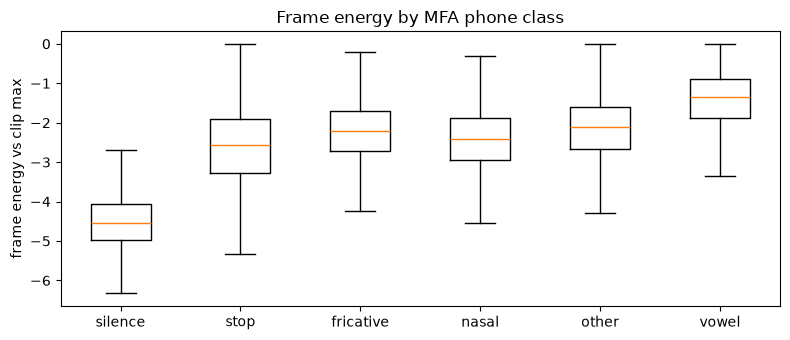

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = ["silence", "stop", "fricative", "nasal", "other", "vowel"]
ax.boxplot([energy[cls == c] for c in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order)
ax.set_ylabel("frame energy vs clip max")
ax.set_title("Frame energy by MFA phone class")
fig.tight_layout()
fig.savefig(FIGURES / "alignment_energy_by_class.png", dpi=110)
plt.show()

## 4 · Durations

What M3 will model. Stress is kept in `phone` (AH0 vs AH1), so the plot strips it to show the
39 base phones.

       count   mean  median    std
phone                             
DH     28383   42.9    34.8   16.2
AH     98912   55.6    46.4   27.1
UH      2861   68.2    58.0   35.5
N      68506   64.8    58.0   32.3
IH     57015   64.4    58.0   29.3
W      20248   65.8    58.0   33.2
B      15642   66.3    58.0   30.2
D      43385   67.8    58.0   32.3
M      23851   79.8    69.7   34.1
HH     14848   74.5    69.7   31.8
G       5987   79.2    69.7   28.3
R      39273   74.9    69.7   40.2
V      19598   73.8    69.7   26.8
Y       4868   78.5    69.7   43.3
T      65609   87.2    81.3   40.7
EH     26806   84.0    81.3   34.2
L      33037   88.1    81.3   42.3
NG      7253   89.3    81.3   34.0
UW     10822  107.4    92.9   60.6
IY     32574  107.8    92.9   55.8
JH      4827  107.8    92.9   48.8
ZH       612   95.7    92.9   22.8
AO      9244  106.5    92.9   56.0
Z      27947   98.8    92.9   39.8
ER     25822  106.6    92.9   55.8
TH      4578  110.7   104.5   46.6
AA     18180  113.4 

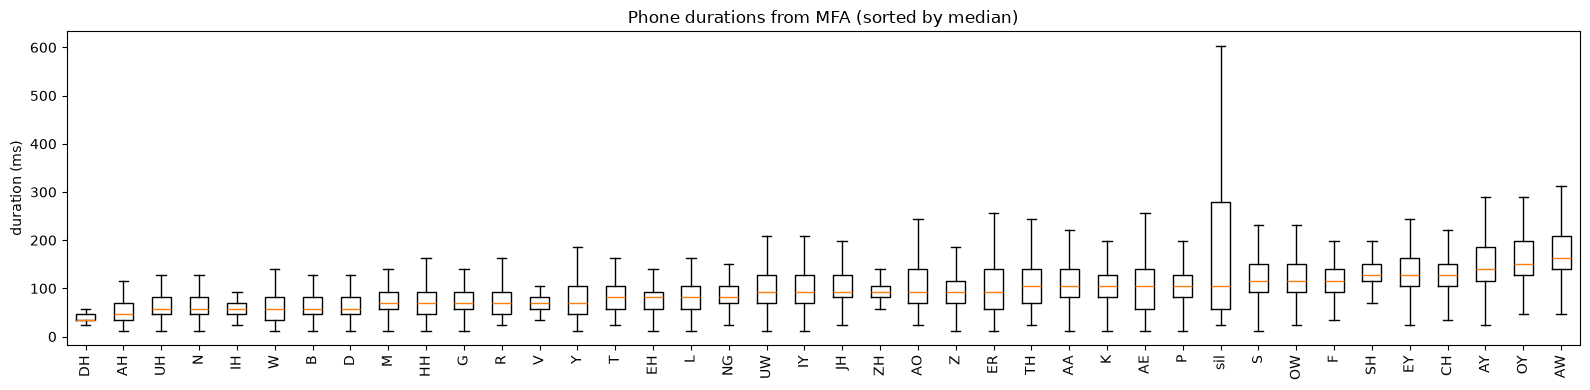

In [7]:
ms = phones.n_frames * SECONDS_PER_FRAME * 1000
base = phones.phone.str.rstrip("012")
stats = ms.groupby(base).agg(["count", "mean", "median", "std"]).round(1).sort_values("median")
print(stats.to_string())

order = stats.index.tolist()
fig, ax = plt.subplots(figsize=(16, 4))
ax.boxplot([ms[base == p] for p in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=90)
ax.set_ylabel("duration (ms)")
ax.set_title("Phone durations from MFA (sorted by median)")
fig.tight_layout()
fig.savefig(FIGURES / "phone_durations.png", dpi=110)
plt.show()

In [8]:
vowels = phones[VOWEL]
stress = vowels.phone.str[-1].map({"0": "unstressed", "1": "primary", "2": "secondary"})
print("vowel duration (ms) by stress - why the stress digit stays in phones.csv:")
print((vowels.n_frames * SECONDS_PER_FRAME * 1000).groupby(stress).describe()[["count", "mean", "50%"]].round(1))

vowel duration (ms) by stress - why the stress digit stays in phones.csv:
               count   mean   50%
phone                            
primary     177038.0  107.8  92.9
secondary    10885.0  101.0  92.9
unstressed  161386.0   66.9  58.0


## 5 · Outliers, for M5's failure log

Where to look first if a clip sounds wrong for alignment reasons (*misaligned phone*). MFA writes
`alignment_analysis.csv` per corpus; low log-likelihood means the audio fits the phones poorly.
Very long non-silence phones are usually drawn-out words or hesitations, or text that does not
match the audio.

In [9]:
analysis = pd.concat([pd.read_csv(p) for p in sorted(Path("data/textgrids").glob("*/alignment_analysis.csv"))])
ll = analysis.set_index("file").overall_log_likelihood
z = (ll - ll.mean()) / ll.std()
print(f"MFA log-likelihood over {len(ll)} clips: mean {ll.mean():.2f}, sd {ll.std():.2f}")
print(f"clips below -3 sd: {(z < -3).sum()}  |  of them in test_100: "
      f"{sorted(set(z[z < -3].index) & set(read_filelist('test_100'))) or 'none'}")

long = phones[(phones.phone != SIL) & (ms > 400)].assign(ms=ms.round())
print(f"\nnon-silence phones over 400 ms: {len(long)} of {(phones.phone != SIL).sum()} "
      f"({len(long) / (phones.phone != SIL).sum():.3%})")
print(long.sort_values("ms", ascending=False).head(10)[["clip_id", "phone", "word", "ms"]].to_string(index=False))
print("\nlowest log-likelihood clips:")
print(ll.nsmallest(10).round(2).to_string())

MFA log-likelihood over 13100 clips: mean -48.37, sd 1.84
clips below -3 sd: 34  |  of them in test_100: none

non-silence phones over 400 ms: 218 of 899497 (0.024%)
   clip_id phone         word    ms
LJ031-0061   ER0       junior 813.0
LJ013-0048   AH0          the 766.0
LJ001-0033     S          mss 708.0
LJ023-0096   EY1            a 673.0
LJ046-0078   AH0          the 650.0
LJ010-0127     D     scaffold 650.0
LJ028-0058   AH0          the 627.0
LJ048-0075     F specifically 557.0
LJ024-0046   AY1            i 546.0
LJ024-0103   OW1           oh 522.0

lowest log-likelihood clips:
file
LJ020-0064   -56.95
LJ014-0165   -56.45
LJ009-0054   -56.11
LJ004-0130   -55.98
LJ011-0205   -55.69
LJ023-0104   -55.40
LJ036-0136   -55.39
LJ002-0177   -55.34
LJ015-0138   -55.10
LJ028-0425   -55.08
